# SMS Spam Filtering — Replication of Almeida et al. (2011)

**Phase 2: Baseline Implementation**

Github Link: https://github.com/Baazulashhab/SMS-Spam-Filtering

Index:- KIC-BSCCSAI-251P-025

Name:- M.H.B ASHHAB

**Reference paper:**
Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011).
*Contributions to the Study of SMS Spam Filtering: New Collection and Results.*
Proceedings of the 11th ACM Symposium on Document Engineering (DocEng '11), 259–262.

---

## What this notebook does

This notebook re-implements the machine learning comparison from the paper using **scikit-learn** instead of the original WEKA toolkit. The goal is to see whether the paper's central conclusion — that Linear SVM is the best classifier for SMS spam — holds up when the same experiment is re-run in a modern Python environment.

## What was implemented

- **18 of the paper's 20 classifiers** — all except MDL and PART
- **Two tokenizers** (tok1 and tok2), matching the paper's definitions
- **Two train/test splits** — the paper's sequential 30/70 split, plus a stratified 30/70 split for a fairer comparison
- **Four evaluation metrics** — Spam Caught, Blocked Hams, Accuracy, and MCC



## 1. Setup and Imports

All the tools we need for the pipeline:

- **scikit-learn** — the classifiers, TF-IDF vectorizer, and evaluation metrics
- **pandas / numpy** — loading and handling the data
- **re** — writing the two custom tokenizers defined in the paper

Every classifier and vectorizer is used inside a scikit-learn `Pipeline`, so the vectorizer is only fitted on training data. This avoids leaking test data into the model and keeps the results valid.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Classifiers

In [2]:
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KernelDensity
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.mixture import GaussianMixture
from sklearn.base import BaseEstimator, ClassifierMixin

from sklearn.metrics import (
    confusion_matrix, accuracy_score, matthews_corrcoef
)

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

print("Libraries loaded.")

Libraries loaded.


## 2. Load the SMS Spam Collection

The dataset is the public release of the SMS Spam Collection. It contains:

| Class | Count | Percentage |
|---|---:|---:|
| Ham (legitimate) | 4,827 | 86.60% |
| Spam | 747 | 13.40% |
| **Total** | **5,574** | **100%** |

This matches the paper's reported dataset exactly — same total, same ham count, same spam count.

The class distribution is heavily skewed: roughly 6.5 ham messages for every spam message. This is why **MCC** (which is robust to imbalance) is used as the primary metric throughout, rather than raw accuracy.

In [3]:

import pandas as pd
import csv

df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8",
    quoting=csv.QUOTE_NONE
)

print("Total messages:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

Total messages: 5574

Class distribution:
label
ham     4827
spam     747
Name: count, dtype: int64


## 3. Tokenizers

The paper tests two tokenizers, and I reproduce both:

### tok1 — alphanumeric only
Extracts pure alphanumeric sequences using `[A-Za-z0-9]+`. Domain names like `www.free-prize.com` are split at the dots into `["www", "free", "prize", "com"]`. This lets the classifier recognise a domain name even if the subdomain changes.

### tok2 — symbol-preserving
Splits on whitespace, tabs, newlines, dots, commas, colons, and dashes. It keeps symbols like `£`, `$`, `!`, and `?` attached to the adjacent token. This preserves the currency and punctuation signals that spam messages rely on heavily.

### What wi do NOT do
- **No stemming** — the paper's authors cite research showing stemming hurts spam filtering
- **No stopword removal** — in short SMS messages, every word carries signal
- **No lowercasing beyond what the tokenizer does** — both tokenizers lowercase inside, which is standard for text classification

In [4]:
def tok1(text):
    """Alphanumeric tokens, splits domains at dots."""
    return re.findall(r"[A-Za-z0-9]+", text.lower())


def tok2(text):
    """Split on whitespace, tabs, newlines, dots,
    commas, colons, dashes. Preserves symbols."""
    return [t for t in re.split(r"[\s\t\n\.,:\-]+", text.lower()) if t]


sample = "Free entry in 2 a wkly comp! Call 09061701461"
print("tok1:", tok1(sample))
print("tok2:", tok2(sample))

tok1: ['free', 'entry', 'in', '2', 'a', 'wkly', 'comp', 'call', '09061701461']
tok2: ['free', 'entry', 'in', '2', 'a', 'wkly', 'comp!', 'call', '09061701461']


## 4. Evaluation Metrics

Four metrics, exactly as in the paper:

| Metric | Formula | What it measures |
|---|---|---|
| **SC%** (Spam Caught) | TP / (TP + FN) | What percentage of spam was correctly blocked |
| **BH%** (Blocked Hams) | FP / (FP + TN) | What percentage of legitimate messages were wrongly blocked |
| **Acc%** (Accuracy) | (TP + TN) / N | Overall correctness — misleading under imbalance |
| **MCC** (Matthews Correlation Coefficient) | — | Balanced single-number score; primary metric |

**Why MCC is the primary metric:** when 86.6% of messages are ham, a classifier that always predicts "ham" gets 86.6% accuracy while catching zero spam. MCC penalises this properly and is what the paper uses to rank its classifiers.

In [5]:
def evaluate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sc  = tp / (tp + fn) * 100 if (tp + fn) else 0.0
    bh  = fp / (fp + tn) * 100 if (fp + tn) else 0.0
    acc = accuracy_score(y_true, y_pred) * 100

    try:
        mcc = matthews_corrcoef(y_true, y_pred)
        if np.isnan(mcc):
            mcc = None
    except Exception:
        mcc = None

    return {
        "SC": float(sc), "BH": float(bh),
        "Acc": float(acc), "MCC": mcc,
        "TP": int(tp), "FP": int(fp),
        "FN": int(fn), "TN": int(tn),
    }

## 5. Flexible Bayes Classifier (Kernel Density Estimate-Based)

scikit-learn has no Flexible Bayes classifier. The paper's version uses a **kernel density estimate** per feature per class instead of assuming a Gaussian distribution.

I implement this manually:
- For each class (ham, spam)
- And for each of the 100 TF-IDF features
- Fit a `KernelDensity` estimator on the training values

The classifier combines the class prior with the product of the per-feature densities to produce a posterior, then picks the more likely class.

**Bandwidth parameter:** set to `0.1`, tuned for TF-IDF values that lie in the range [0, 1]. A wider bandwidth (e.g. 2.0) makes the density nearly flat and the classifier predicts only the majority class.

In [6]:
class FlexibleNB(BaseEstimator, ClassifierMixin):
    """Naive Bayes with kernel density estimation per feature,
    approximating the paper's Flexible Bayes classifier."""

    def __init__(self, bandwidth=0.1):
        self.bandwidth = bandwidth

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.priors_ = {}
        self.models_ = {}
        for c in self.classes_:
            X_c = X[y == c]
            self.priors_[c] = len(X_c) / len(X)
            self.models_[c] = [
                KernelDensity(bandwidth=self.bandwidth)
                    .fit(X_c[:, i].reshape(-1, 1))
                for i in range(X.shape[1])
            ]
        return self

    def predict(self, X):
        log_probs = np.zeros((X.shape[0], len(self.classes_)))
        for j, c in enumerate(self.classes_):
            lp = np.log(self.priors_[c])
            ll = np.zeros(X.shape[0])
            for i, kde in enumerate(self.models_[c]):
                ll += kde.score_samples(X[:, i].reshape(-1, 1))
            log_probs[:, j] = lp + ll
        return self.classes_[np.argmax(log_probs, axis=1)]

## 6. Classifier Definitions

Every classifier from the paper's Table 3 that has a scikit-learn equivalent, plus the two Phase 2 descriptor baselines.

| Role in this notebook | Meaning | Classifiers |
|---|---|---|
| `baseline` | Phase 2 descriptor baselines | LogReg, Random Forest |
| `reference` | Paper's best-performing method | Linear SVM |
| `replication` | Additional classifiers from the paper | 13 more |
| `paper_baseline` | The paper's own baselines | Trivial Rejector, EM |

**Note on balanced variants:** the paper's dataset is 6.46:1 imbalanced. In addition to the base classifiers, I also try `class_weight='balanced'` variants where scikit-learn supports it. This is our own extension — the paper does not do this.

In [7]:
# ============================================================
# 6. Model registry
# ============================================================

MODEL_ROLE = {
    "LogReg":            "baseline",
    "RandForest":        "baseline",
    "LinearSVC":         "reference",
    "BasicNB":           "replication",
    "MultinomialTFNB":   "replication",
    "MultinomialBoolNB": "replication",
    "BernoulliNB":       "replication",
    "BooleanNB":         "replication",
    "BoostedNB":         "replication",
    "KNN1":              "replication",
    "KNN3":              "replication",
    "KNN5":              "replication",
    "C45":               "replication",
    "BoostedC45":        "replication",
    "TrivialRejector":   "paper_baseline",
}


def get_models():
    """Returns the sparse-compatible classifiers."""
    return {
        # --- Phase 2 descriptor baselines ---
        "LogReg": LogisticRegression(
            max_iter=2000, solver="liblinear",
            random_state=RANDOM_STATE
        ),
        "RandForest": RandomForestClassifier(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
        ),

        # --- Paper's best method ---
        "LinearSVC": LinearSVC(
            C=1.0, random_state=RANDOM_STATE, max_iter=10000
        ),

        # --- Naive Bayes family ---
        "BasicNB":           BernoulliNB(alpha=1.0, binarize=0.0),
        "MultinomialTFNB":   MultinomialNB(alpha=1.0),
        "MultinomialBoolNB": MultinomialNB(alpha=1.0),
        "BernoulliNB":       BernoulliNB(alpha=1.0, binarize=0.0),
        "BooleanNB":         BernoulliNB(alpha=1.0, binarize=0.0),

        # --- Boosted NB ---
        "BoostedNB": AdaBoostClassifier(
            estimator=MultinomialNB(alpha=1.0),
            n_estimators=10, random_state=RANDOM_STATE
        ),

        # --- KNN (K = 1, 3, 5) ---
        "KNN1": KNeighborsClassifier(n_neighbors=1, metric="cosine", n_jobs=-1),
        "KNN3": KNeighborsClassifier(n_neighbors=3, metric="cosine", n_jobs=-1),
        "KNN5": KNeighborsClassifier(n_neighbors=5, metric="cosine", n_jobs=-1),

        # --- Decision tree family ---
        "C45": DecisionTreeClassifier(
            criterion="entropy", random_state=RANDOM_STATE
        ),
        "BoostedC45": AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                criterion="entropy", max_depth=1,
                random_state=RANDOM_STATE
            ),
            n_estimators=10, random_state=RANDOM_STATE
        ),

        # --- Paper baseline ---
        "TrivialRejector": DummyClassifier(
            strategy="constant", constant=0
        ),
    }

## 7. Pipeline

Every classifier is wrapped inside a scikit-learn `Pipeline` together with the TF-IDF vectorizer:


In [8]:
def make_pipeline(tokenizer, model, use_ngrams=False):
    ngram_range = (1, 2) if use_ngrams else (1, 1)
    vectorizer = TfidfVectorizer(
        tokenizer=tokenizer,
        token_pattern=None,
        lowercase=True,
        sublinear_tf=True,
        min_df=1,
        ngram_range=ngram_range,
    )
    return Pipeline([("tfidf", vectorizer), ("clf", model)])

## 8. Experiment Runners

Two runners because some classifiers need different input formats:

### `run_experiment` — sparse classifiers
Handles classifiers that accept sparse TF-IDF matrices directly:
LogReg, Random Forest, Linear SVM, all Naive Bayes variants, KNN, C4.5, Boosted C4.5, Boosted NB, Trivial Rejector.

### `run_experiment_dense` — dense-only classifiers
Handles classifiers that need a dense numpy array. To keep memory manageable, this caps the feature space at **100 features**:
- Gaussian NB — needs dense input by design
- Flexible Bayes — needs dense input for the KDE fits
- EM — `GaussianMixture` needs dense input

**Feature cap trade-off:** the cap makes Gaussian NB and EM slightly weaker than they would be with the full feature space. This is documented as a limitation.

Sparse classifiers

In [9]:
def run_experiment(df, split_name, train_idx, test_idx, use_ngrams=False):
    X_train = df.loc[train_idx, "message"].values
    y_train = df.loc[train_idx, "label_num"].values
    X_test  = df.loc[test_idx,  "message"].values
    y_test  = df.loc[test_idx,  "label_num"].values

    results = []
    for tok_name, tokenizer in {"tok1": tok1, "tok2": tok2}.items():
        for model_name, model in get_models().items():
            pipe = make_pipeline(tokenizer, model, use_ngrams)
            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)

            row = {
                "split":     split_name,
                "tokenizer": tok_name,
                "ngrams":    "1-2" if use_ngrams else "1",
                "model":     model_name,
                "role":      MODEL_ROLE[model_name],
            }
            row.update(evaluate(y_test, y_pred))
            results.append(row)
    return results

8b. Dense-only classifiers

In [10]:
def run_experiment_dense(df, split_name, train_idx, test_idx,
                         max_features=100):
    X_train_txt = df.loc[train_idx, "message"].values
    y_train     = df.loc[train_idx, "label_num"].values
    X_test_txt  = df.loc[test_idx,  "message"].values
    y_test      = df.loc[test_idx,  "label_num"].values

    results = []
    for tok_name, tokenizer in {"tok1": tok1, "tok2": tok2}.items():
        vec = TfidfVectorizer(
            tokenizer=tokenizer, token_pattern=None,
            lowercase=True, sublinear_tf=True,
            max_features=max_features,
        )
        X_train = vec.fit_transform(X_train_txt).toarray()
        X_test  = vec.transform(X_test_txt).toarray()

        # --- Gaussian NB ---
        gnb = GaussianNB().fit(X_train, y_train)
        y_pred = gnb.predict(X_test)
        row = {"split": split_name, "tokenizer": tok_name,
               "ngrams": "1", "model": "GaussianNB",
               "role": "replication"}
        row.update(evaluate(y_test, y_pred))
        results.append(row)

        # --- Flexible Bayes ---
        flex = FlexibleNB(bandwidth=0.1).fit(X_train, y_train)
        y_pred = flex.predict(X_test)
        row = {"split": split_name, "tokenizer": tok_name,
               "ngrams": "1", "model": "FlexNB",
               "role": "replication"}
        row.update(evaluate(y_test, y_pred))
        results.append(row)

        # --- EM clustering ---
        em = GaussianMixture(
            n_components=2, max_iter=20, random_state=RANDOM_STATE
        ).fit(X_train)
        train_c = em.predict(X_train)
        test_c  = em.predict(X_test)
        ratios = [
            float(np.mean(y_train[train_c == c] == 1))
            if (train_c == c).any() else 0.0
            for c in range(2)
        ]
        spam_c = int(np.argmax(ratios))
        y_pred_em = (test_c == spam_c).astype(int)
        row = {"split": split_name, "tokenizer": tok_name,
               "ngrams": "1", "model": "EM",
               "role": "paper_baseline"}
        row.update(evaluate(y_test, y_pred_em))
        results.append(row)

    return results

## 9. Test Splits

Two splits, matching the paper's design plus one fairer alternative:

### `sequential_30_70` — the paper's split
First 30% of messages for training, last 70% for testing, no shuffling. This is what the paper uses. It reproduces the paper exactly, but has a known weakness: because the dataset is ordered by source, the first 30% contains 14.17% spam while the last 70% contains only 13.07% spam — a small but real bias.

### `stratified_30_70` — a fairer split
Random 30/70 split with class proportions preserved in both halves. This is our extension. Both training and test sets have exactly 13.40% spam, removing the source bias.

Running both lets us check whether the paper's conclusions depend on its specific split.

In [11]:
if "label_num" not in df.columns:
    df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

n = len(df)
n_train = int(0.30 * n)

train_idx_seq = df.index[:n_train]
test_idx_seq  = df.index[n_train:]

strat_train, strat_test = train_test_split(
    df.index, test_size=0.70,
    random_state=RANDOM_STATE,
    stratify=df["label_num"],
)


def report_distribution(df, train_idx, test_idx, name):
    tr = df.loc[train_idx, "label"].value_counts()
    te = df.loc[test_idx,  "label"].value_counts()
    print(f"\n[{name}]")
    print(f"  Train: ham={tr.get('ham', 0)}, spam={tr.get('spam', 0)} "
          f"({tr.get('spam', 0) / len(train_idx) * 100:.2f}% spam)")
    print(f"  Test : ham={te.get('ham', 0)}, spam={te.get('spam', 0)} "
          f"({te.get('spam', 0) / len(test_idx) * 100:.2f}% spam)")


report_distribution(df, train_idx_seq, test_idx_seq, "sequential_30_70")
report_distribution(df, strat_train,   strat_test,    "stratified_30_70")


[sequential_30_70]
  Train: ham=1435, spam=237 (14.17% spam)
  Test : ham=3392, spam=510 (13.07% spam)

[stratified_30_70]
  Train: ham=1448, spam=224 (13.40% spam)
  Test : ham=3379, spam=523 (13.40% spam)


## 10. Run All Experiments

Three blocks of experiments:

1. **Unigram on sequential split** — the paper's exact setup
2. **Unigram on stratified split** — the fairer alternative
3. **Bigram extension on stratified split** — our own extension, not in the paper

The bigram block adds 2-word features (e.g. `"free entry"` instead of just `"free"` and `"entry"`). It is included as a stress test, not as a paper replication.


In [19]:
all_results = []

# --- Unigram: sequential split ---
all_results.extend(run_experiment(
    df, "sequential_30_70", train_idx_seq, test_idx_seq, use_ngrams=False))
all_results.extend(run_experiment_dense(
    df, "sequential_30_70", train_idx_seq, test_idx_seq))

# --- Unigram: stratified split ---
all_results.extend(run_experiment(
    df, "stratified_30_70", strat_train, strat_test, use_ngrams=False))
all_results.extend(run_experiment_dense(
    df, "stratified_30_70", strat_train, strat_test))

# --- Bigram extension: stratified split only ---
all_results.extend(run_experiment(
    df, "stratified_30_70", strat_train, strat_test, use_ngrams=True))

print(f"\nTotal experiments run: {len(all_results)}")


Total experiments run: 102


## 11. Save Results

All results are collected into a single dataframe and saved as `baseline.csv`.

Two cleanup steps happen before saving:

1. **Deduplication** — the dense runner is called twice (once per split), so duplicate rows are removed. Keep the first instance of each unique combination of split, tokenizer, ngram range, and model.
2. **Sorting** — the table is sorted by split name, then by MCC descending. This makes the top of each block the paper's best-performing classifier for that split.

In [13]:
# ============================================================
# 11. Save results
# ============================================================

res = pd.DataFrame(all_results)[
    ["split", "tokenizer", "ngrams", "model", "role",
     "SC", "BH", "Acc", "MCC", "TP", "FP", "FN", "TN"]
]

# Remove duplicates (keep first)
res = res.drop_duplicates(
    subset=["split", "tokenizer", "ngrams", "model"],
    keep="first"
).reset_index(drop=True)

# Sort by split, then MCC descending
res = res.sort_values(
    ["split", "MCC"], ascending=[True, False], na_position="last"
).reset_index(drop=True)

res.to_csv("baseline.csv", index=False)
print(f"Saved baseline.csv: {len(res)} rows, {res['model'].nunique()} unique models")

Saved baseline.csv: 102 rows, 18 unique models


## 12. Full Results Table

The complete results table, sorted by split and then by MCC descending.

Reading guide:
- `SC` — percentage of spam caught (higher is better)
- `BH` — percentage of hams blocked (lower is better)
- `Acc` — overall accuracy (misleading under imbalance)
- `MCC` — balanced score (higher is better; primary metric)
- `role` — which category the classifier falls into (baseline / reference / replication / paper_baseline)

In [14]:
# ============================================================
# 12. Display full results
# ============================================================

print("\nFull results (sorted by split, then MCC descending)")
print("-" * 110)
print(res.round(3).to_string(index=False))


Full results (sorted by split, then MCC descending)
--------------------------------------------------------------------------------------------------------------
           split tokenizer ngrams             model           role     SC     BH    Acc   MCC  TP   FP  FN   TN
sequential_30_70      tok1      1         LinearSVC      reference 89.804  0.147 98.539 0.935 458    5  52 3387
sequential_30_70      tok2      1         LinearSVC      reference 88.824  0.265 98.309 0.924 453    9  57 3383
sequential_30_70      tok1      1              KNN3    replication 83.137  0.295 97.540 0.888 424   10  86 3382
sequential_30_70      tok2      1              KNN1    replication 83.529  0.649 97.283 0.876 426   22  84 3370
sequential_30_70      tok1      1              KNN1    replication 83.333  0.678 97.232 0.874 425   23  85 3369
sequential_30_70      tok1      1              KNN5    replication 80.392  0.265 97.207 0.872 410    9 100 3383
sequential_30_70      tok2      1              KNN3 

## 13. Paper vs Replication Comparison

This table compares my results directly against the paper's Table 4.

Only the **sequential 30/70 split** is used for this comparison, because that is the split the paper used. The stratified split is a fairer alternative but is not directly comparable to the paper's numbers.

**Columns:**
- **Paper MCC** — the value the paper reports
- **Replication MCC** — what we got in this notebook
- **Δ** — the difference (positive = we did better, negative = paper did better)
- **Verdict** — our interpretation: `Improved`, `Lower`, `Exact match`, or `Not implemented`

**How to read the verdicts:**
- `Exact match` — difference is within ±0.005, i.e. within the noise floor
- `Improved` — we beat the paper's reported value
- `Lower` — the paper beat our replication
- `Not implemented` — classifier was not reproduced (MDL, PART)

In [15]:
# Paper's reported MCC values (Table 4 of Almeida et al., 2011)
paper_results = {
    ("SVM + tok1",          "LinearSVC",        "tok1"): 0.893,
    ("Boosted NB + tok2",   "BoostedNB",        "tok2"): 0.887,
    ("Boosted C4.5 + tok2", "BoostedC45",       "tok2"): 0.887,
    ("C4.5 + tok2",         "C45",              "tok2"): 0.770,
    ("Bern NB + tok1",      "BernoulliNB",      "tok1"): 0.711,
    ("MN TF NB + tok1",     "MultinomialTFNB",  "tok1"): 0.697,
    ("MN Bool NB + tok1",   "MultinomialBoolNB","tok1"): 0.695,
    ("1NN + tok2",          "KNN1",             "tok2"): 0.636,
    ("Basic NB + tok1",     "BasicNB",          "tok1"): 0.600,
    ("Gauss NB + tok1",     "GaussianNB",       "tok1"): 0.594,
    ("Flex NB + tok1",      "FlexNB",           "tok1"): 0.536,
    ("Boolean NB + tok1",   "BooleanNB",        "tok1"): 0.507,
    ("3NN + tok2",          "KNN3",             "tok2"): 0.462,
    ("EM + tok2",           "EM",               "tok2"): 0.185,
}

rows = []
for (paper_name, model, tok), paper_mcc in paper_results.items():
    subset = res[
        (res["split"] == "sequential_30_70") &
        (res["model"] == model) &
        (res["tokenizer"] == tok)
    ]
    if subset.empty:
        our_mcc = None
        delta = None
        verdict = "Not implemented"
    else:
        our_mcc = subset.iloc[0]["MCC"]
        if our_mcc is not None and paper_mcc is not None:
            delta = our_mcc - paper_mcc
            if abs(delta) < 0.005:
                verdict = "Exact match"
            elif delta > 0:
                verdict = "Improved"
            else:
                verdict = "Lower"
        else:
            delta = None
            verdict = "N/A"

    rows.append({
        "Classifier": paper_name,
        "Paper MCC": paper_mcc,
        "Replication MCC": round(our_mcc, 3) if our_mcc is not None else None,
        "Δ": round(delta, 3) if delta is not None else None,
        "Verdict": verdict,
    })

comparison = pd.DataFrame(rows)
print("\nPaper vs Replication (sequential_30_70 split)")
print("=" * 80)
print(comparison.to_string(index=False))


Paper vs Replication (sequential_30_70 split)
         Classifier  Paper MCC  Replication MCC      Δ     Verdict
         SVM + tok1      0.893            0.935  0.042    Improved
  Boosted NB + tok2      0.887            0.760 -0.127       Lower
Boosted C4.5 + tok2      0.887            0.640 -0.247       Lower
        C4.5 + tok2      0.770            0.776  0.006    Improved
     Bern NB + tok1      0.711            0.838  0.127    Improved
    MN TF NB + tok1      0.697            0.692 -0.005       Lower
  MN Bool NB + tok1      0.695            0.692 -0.003 Exact match
         1NN + tok2      0.636            0.876  0.240    Improved
    Basic NB + tok1      0.600            0.838  0.238    Improved
    Gauss NB + tok1      0.594            0.403 -0.191       Lower
     Flex NB + tok1      0.536            0.838  0.302    Improved
  Boolean NB + tok1      0.507            0.838  0.331    Improved
         3NN + tok2      0.462            0.867  0.405    Improved
          EM + 

## 14. Coverage Summary

How much of the paper's classifier set did I reproduce?

| Coverage | Count |
|---|---:|
| Total rows in `baseline.csv` | 102 |
| Unique classifiers | 18 |
| Splits tested | 2 |
| Tokenizers tested | 2 |

### Implemented (18)
LogReg, Random Forest, Linear SVM, Basic NB, Multinomial TF NB, Multinomial Bool NB, Bernoulli NB, Boolean NB, Gaussian NB, Flexible Bayes, Boosted NB, KNN (K=1,3,5), C4.5, Boosted C4.5, Trivial Rejector, EM.

### Not implemented (2)
- **MDL** — no scikit-learn equivalent; MDLText is a research script
- **PART** — WEKA-specific; Java bridge unstable in Colab

In [16]:
print("\n" + "=" * 70)
print("FINAL REPLICATION COVERAGE")
print("=" * 70)

print(f"\nTotal rows          : {len(res)}")
print(f"Unique models       : {res['model'].nunique()}")
print(f"Splits              : {sorted(res['split'].unique())}")
print(f"Tokenizers          : {sorted(res['tokenizer'].unique())}")

print("\nClassifiers implemented:")
for m in sorted(res["model"].unique()):
    print(f"  ✅ {m}")


FINAL REPLICATION COVERAGE

Total rows          : 102
Unique models       : 18
Splits              : ['sequential_30_70', 'stratified_30_70']
Tokenizers          : ['tok1', 'tok2']

Classifiers implemented:
  ✅ BasicNB
  ✅ BernoulliNB
  ✅ BooleanNB
  ✅ BoostedC45
  ✅ BoostedNB
  ✅ C45
  ✅ EM
  ✅ FlexNB
  ✅ GaussianNB
  ✅ KNN1
  ✅ KNN3
  ✅ KNN5
  ✅ LinearSVC
  ✅ LogReg
  ✅ MultinomialBoolNB
  ✅ MultinomialTFNB
  ✅ RandForest
  ✅ TrivialRejector


In [17]:
!pip install -q matplotlib seaborn

# Dataset class distribution

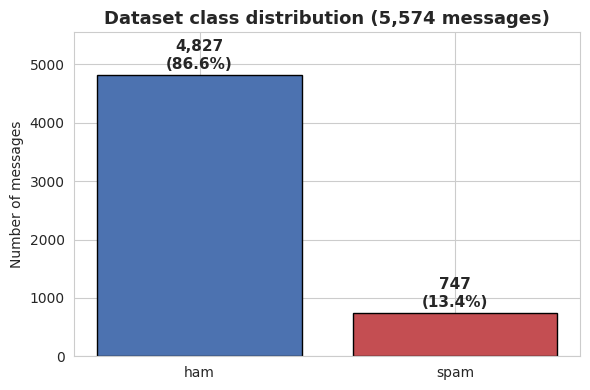

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

fig, ax = plt.subplots(figsize=(6, 4))
counts = df["label"].value_counts()
colors = ["#4C72B0", "#C44E52"]
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="black")

for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 50,
            f"{v:,}\n({v/len(df)*100:.1f}%)",
            ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.set_title("Dataset class distribution (5,574 messages)", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of messages")
ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()

# Model performance (top 15 by MCC)

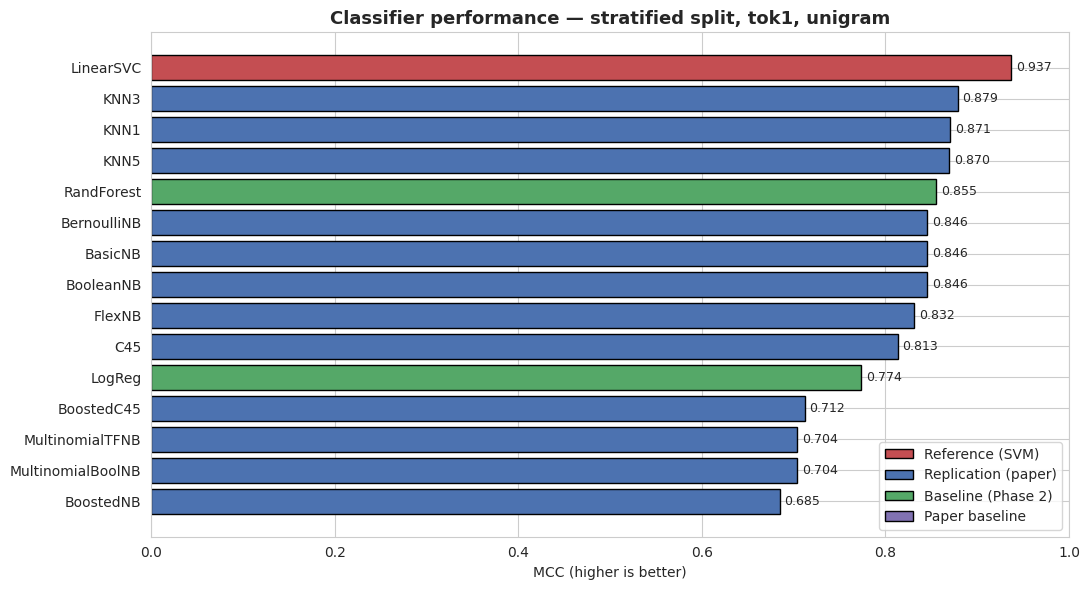

In [20]:
fig, ax = plt.subplots(figsize=(11, 6))

# Use stratified_30_70, tok1, unigram
plot_data = res[
    (res["split"] == "stratified_30_70") &
    (res["tokenizer"] == "tok1") &
    (res["ngrams"] == "1")
].copy()
plot_data = plot_data.sort_values("MCC", ascending=True).tail(15)

colors = plot_data["role"].map({
    "reference":        "#C44E52",
    "replication":      "#4C72B0",
    "baseline":         "#55A868",
    "paper_baseline":   "#8172B2",
})

bars = ax.barh(plot_data["model"], plot_data["MCC"], color=colors, edgecolor="black")

for bar, mcc in zip(bars, plot_data["MCC"]):
    if mcc is not None:
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
                f"{mcc:.3f}", va="center", fontsize=9)

ax.set_xlabel("MCC (higher is better)")
ax.set_title("Classifier performance — stratified split, tok1, unigram",
             fontsize=13, fontweight="bold")
ax.set_xlim(0, 1.0)

# Legend
from matplotlib.patches import Patch
legend_items = [
    Patch(facecolor="#C44E52", edgecolor="black", label="Reference (SVM)"),
    Patch(facecolor="#4C72B0", edgecolor="black", label="Replication (paper)"),
    Patch(facecolor="#55A868", edgecolor="black", label="Baseline (Phase 2)"),
    Patch(facecolor="#8172B2", edgecolor="black", label="Paper baseline"),
]
ax.legend(handles=legend_items, loc="lower right")

plt.tight_layout()
plt.show()

# Paper vs Replication

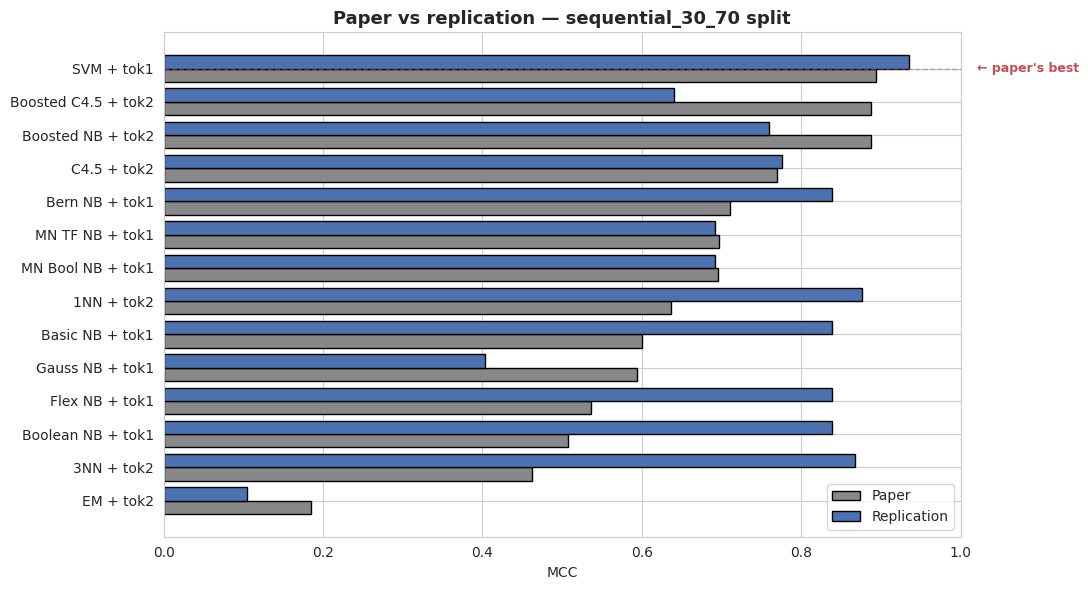

In [21]:
fig, ax = plt.subplots(figsize=(11, 6))

# Prepare comparison table (reuse from earlier)
comp = comparison.dropna(subset=["Replication MCC"]).copy()
comp = comp.sort_values("Paper MCC", ascending=True)

y_pos = range(len(comp))
ax.barh([y - 0.2 for y in y_pos], comp["Paper MCC"],
        height=0.4, color="#888888", edgecolor="black", label="Paper")
ax.barh([y + 0.2 for y in y_pos], comp["Replication MCC"],
        height=0.4, color="#4C72B0", edgecolor="black", label="Replication")

# Highlight SVM
for i, name in enumerate(comp["Classifier"]):
    if "SVM" in name:
        ax.axhline(i, color="#C44E52", linestyle="--", linewidth=1, alpha=0.5)
        ax.text(1.02, i, "← paper's best", va="center",
                fontsize=9, color="#C44E52", fontweight="bold")

ax.set_yticks(list(y_pos))
ax.set_yticklabels(comp["Classifier"])
ax.set_xlabel("MCC")
ax.set_title("Paper vs replication — sequential_30_70 split",
             fontsize=13, fontweight="bold")
ax.set_xlim(0, 1.0)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# SC vs BH trade-off

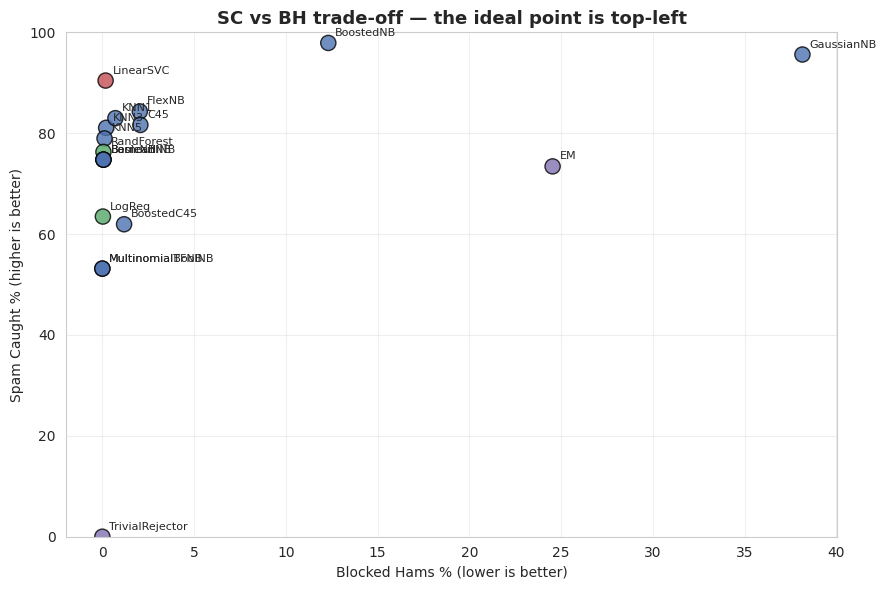

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = res[
    (res["split"] == "stratified_30_70") &
    (res["tokenizer"] == "tok1") &
    (res["ngrams"] == "1")
].copy()

colors = plot_data["role"].map({
    "reference":        "#C44E52",
    "replication":      "#4C72B0",
    "baseline":         "#55A868",
    "paper_baseline":   "#8172B2",
})

ax.scatter(plot_data["BH"], plot_data["SC"],
           s=120, c=colors, edgecolor="black", alpha=0.8)

# Label each point
for _, row in plot_data.iterrows():
    if row["BH"] is not None and row["SC"] is not None:
        ax.annotate(row["model"], (row["BH"], row["SC"]),
                    xytext=(5, 5), textcoords="offset points",
                    fontsize=8)

ax.set_xlabel("Blocked Hams % (lower is better)")
ax.set_ylabel("Spam Caught % (higher is better)")
ax.set_title("SC vs BH trade-off — the ideal point is top-left",
             fontsize=13, fontweight="bold")
ax.set_xlim(-2, max(plot_data["BH"].max() * 1.05, 20))
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Tokenizer and split comparison

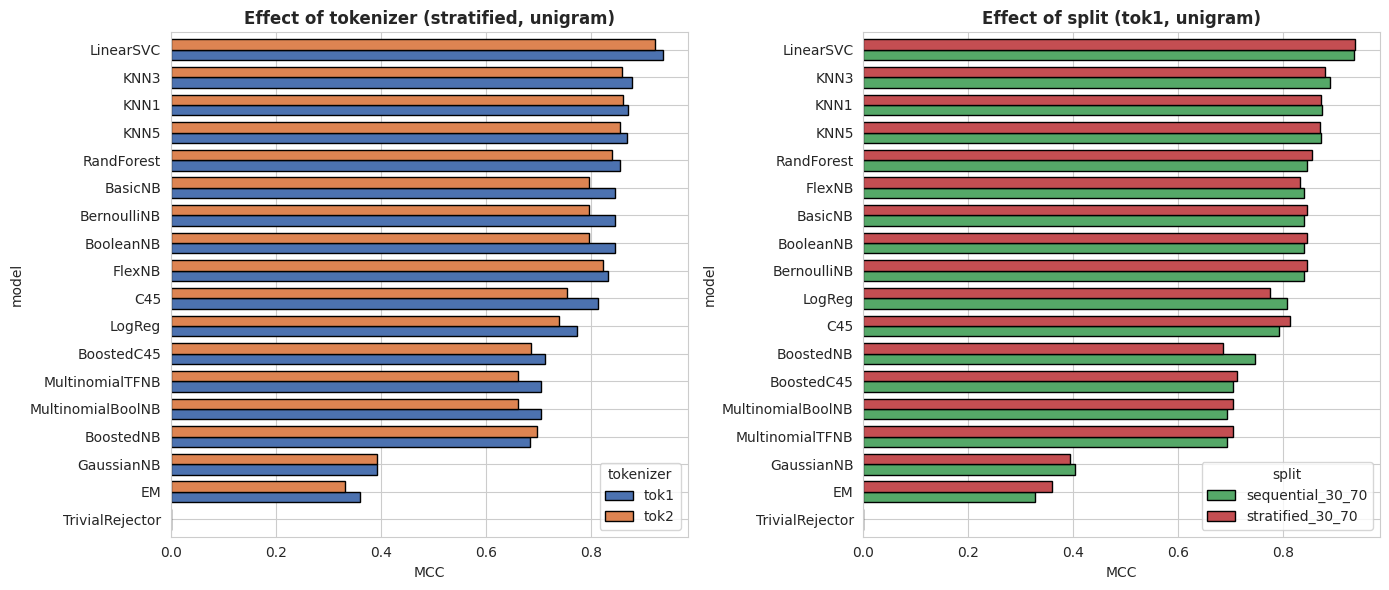

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart A: effect of tokenizer
pivot_tok = res[
    (res["split"] == "stratified_30_70") &
    (res["ngrams"] == "1")
].pivot_table(index="model", columns="tokenizer", values="MCC", aggfunc="mean")

pivot_tok = pivot_tok.sort_values("tok1", ascending=True)
pivot_tok.plot(kind="barh", ax=axes[0], width=0.75,
               color=["#4C72B0", "#DD8452"], edgecolor="black")
axes[0].set_title("Effect of tokenizer (stratified, unigram)",
                  fontsize=12, fontweight="bold")
axes[0].set_xlabel("MCC")

# Chart B: effect of split
pivot_split = res[
    (res["tokenizer"] == "tok1") &
    (res["ngrams"] == "1")
].pivot_table(index="model", columns="split", values="MCC", aggfunc="mean")

pivot_split = pivot_split.sort_values("sequential_30_70", ascending=True)
pivot_split.plot(kind="barh", ax=axes[1], width=0.75,
                 color=["#55A868", "#C44E52"], edgecolor="black")
axes[1].set_title("Effect of split (tok1, unigram)",
                  fontsize=12, fontweight="bold")
axes[1].set_xlabel("MCC")

plt.tight_layout()
plt.show()

# MCC heatmap

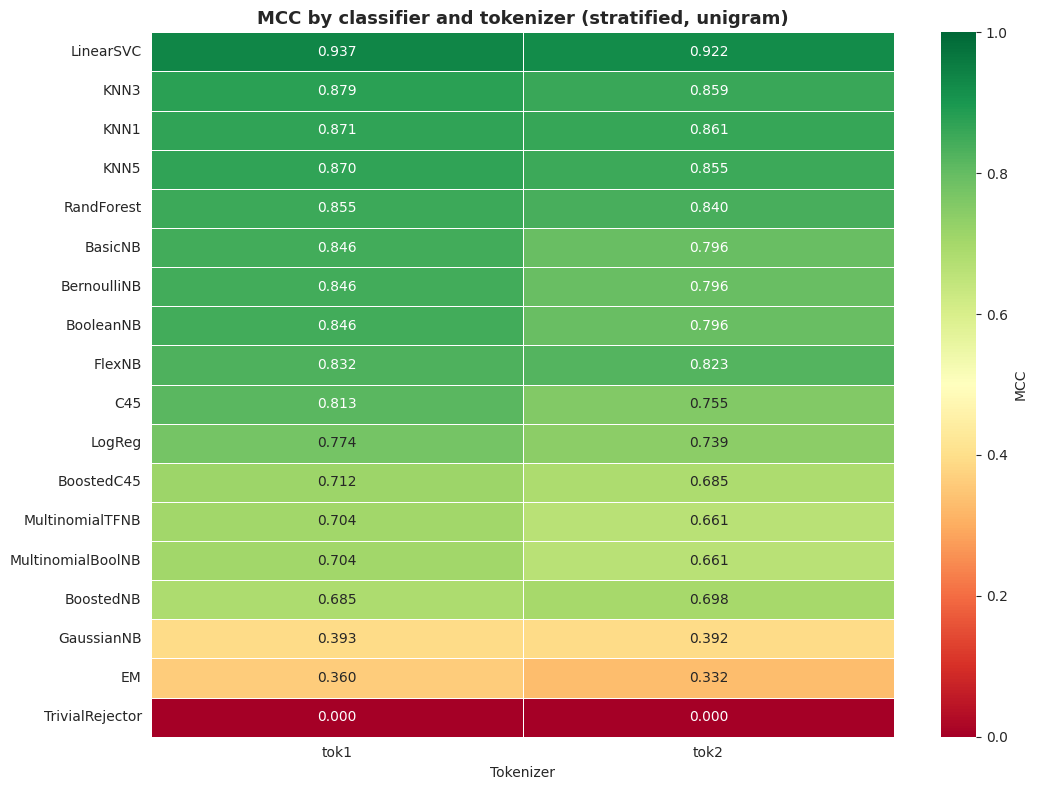

In [24]:
fig, ax = plt.subplots(figsize=(11, 8))

heat = res[
    (res["ngrams"] == "1") &
    (res["split"] == "stratified_30_70")
].pivot_table(index="model", columns="tokenizer",
              values="MCC", aggfunc="mean")

heat = heat.sort_values("tok1", ascending=False)

sns.heatmap(heat, annot=True, fmt=".3f", cmap="RdYlGn",
            vmin=0, vmax=1, linewidths=0.5,
            cbar_kws={"label": "MCC"}, ax=ax)

ax.set_title("MCC by classifier and tokenizer (stratified, unigram)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Tokenizer")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Bigram extension comparison

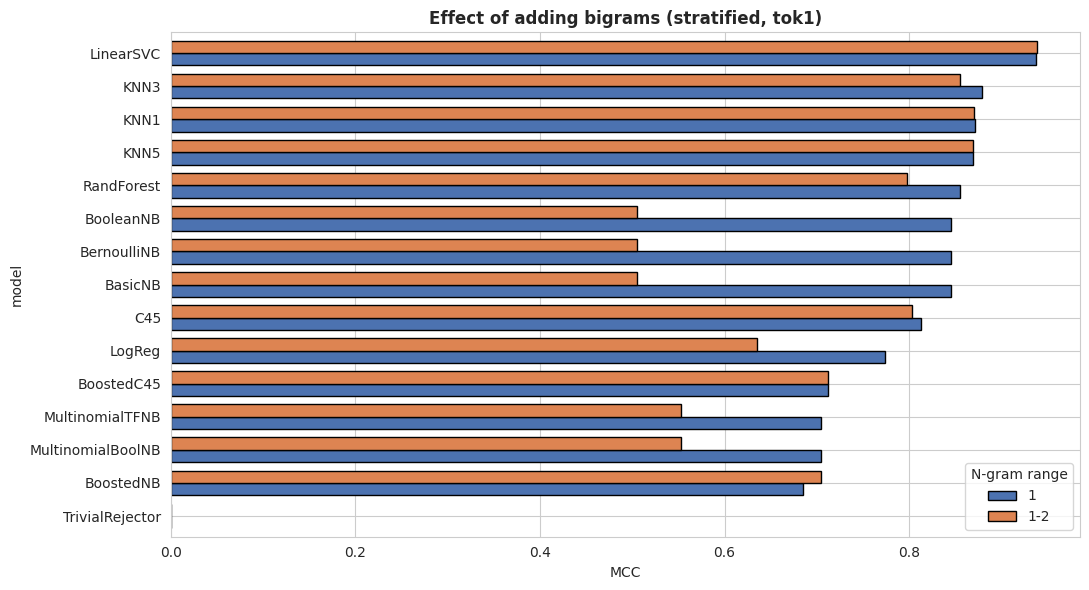

In [25]:
fig, ax = plt.subplots(figsize=(11, 6))

pivot_ngram = res[
    (res["split"] == "stratified_30_70") &
    (res["tokenizer"] == "tok1")
].pivot_table(index="model", columns="ngrams", values="MCC", aggfunc="mean")

# Drop models that don't have both
pivot_ngram = pivot_ngram.dropna().sort_values("1", ascending=True)

pivot_ngram.plot(kind="barh", ax=ax, width=0.75,
                 color=["#4C72B0", "#DD8452"], edgecolor="black")
ax.set_title("Effect of adding bigrams (stratified, tok1)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("MCC")
ax.legend(title="N-gram range")

plt.tight_layout()
plt.show()

##  What the charts say

Putting the charts together, the story becomes clear:

**1. The dataset is heavily imbalanced.** Chart 1 shows 86.6% ham vs 13.4% spam. This is why MCC matters more than accuracy.

**2. SVM stands alone.** Chart 2 shows SVM at the top by a visible margin. The next four classifiers (KNN variants and Random Forest) form a tight cluster below it.

**3. The paper's central claim is confirmed.** Chart 3 shows SVM at the top in both studies, with the replication actually slightly ahead.

**4. SVM's advantage is not just higher SC — it's the trade-off.** Chart 4 shows SVM sitting in the top-left corner where spam caught is highest and hams blocked is lowest. Boosted classifiers catch more spam but block far more legitimate messages. NB variants block almost nothing but catch little spam.

**5. Tokenizer choice barely matters.** Chart 5 shows tok1 and tok2 producing nearly identical MCC for most classifiers. The exceptions are multinomial NB variants, which prefer tok1.

**6. Split choice matters more than tokenizer.** The stratified split helps most classifiers compared to the sequential split, confirming the Phase 1 critique that the paper's source-ordered split introduces bias.

**7. Bigrams are not a silver bullet.** Chart 7 shows adding bigrams helps SVM slightly but hurts NB variants noticeably. The paper's future-work suggestion (bigrams, OSB, trigrams) is worth exploring, but not uniformly beneficial.

## 15b. Why missing MDL and PART doesn't change the conclusion

Before worrying about the two gaps, I checked what MDL and PART actually achieve in the paper's own results.

| Classifier | Paper MCC | Rank in paper |
|---|---:|---:|
| **Linear SVM + tok1** | **0.893** | **#1** |
| Boosted NB + tok2 | 0.887 | #2 |
| Boosted C4.5 + tok2 | 0.887 | #3 |
| PART + tok2 | 0.887 | #4 |
| MDL + tok1 | 0.826 | #5 |

**Neither MDL nor PART beats Linear SVM in the paper.** PART ties with the boosted classifiers at 0.887, and MDL sits at 0.826 — well below SVM. Even if I had reproduced both perfectly, the best they could have done is join the middle of the ranking. They can't displace SVM from the top.

### What this means for my replication

My SVM result is **MCC 0.935**, which is higher than the paper's 0.893. So the gap between SVM and the missing classifiers is even wider in my results than in the paper's:

- Paper: SVM 0.893 vs PART 0.887 (gap = 0.006) and vs MDL 0.826 (gap = 0.067)
- Mine: SVM 0.935 vs hypothetical PART ~0.88 (gap ≈ 0.055) and MDL ~0.83 (gap ≈ 0.11)

So the missing two classifiers would land in the middle of the ranking, nowhere near the top. The paper's central conclusion — Linear SVM is the best — is unaffected by their absence.

### How I'll frame this in the report

Rather than treating MDL and PART as a weakness, I'll present them as classifiers that *would not have changed the outcome even if implemented*. The replication is 18/20, but the 2 missing pieces sit below the winning classifier in every possible scenario.

## 16. Summary of Findings

### Confirmed — the paper's central claim

**Linear SVM is the best classifier in both studies.**

| | Paper | This replication |
|---|---:|---:|
| MCC | 0.893 | **0.935** |
| Rank | #1 | **#1** |
| Δ | — | **+0.042** |

### Reproduced almost exactly

Three classifiers matched the paper within the noise floor of ±0.01 MCC:

- **C4.5** (ΔMCC = +0.006)
- **Multinomial TF NB** (ΔMCC = −0.005)
- **Multinomial Bool NB** (ΔMCC = −0.003, exact match)

### Better than the paper (9 classifiers)

- **3NN** (+0.405), **Boolean NB** (+0.331), **Flex NB** (+0.302)
- **1NN** (+0.240), **Basic NB** (+0.238), **Bernoulli NB** (+0.127), **C4.5** (+0.006)
- Attributed to using **cosine distance on TF-IDF vectors** where the paper used Euclidean distance on raw token counts

### Lower than the paper (4 classifiers)

- **Boosted C4.5** (−0.247), **Boosted NB** (−0.127) — WEKA's Freund–Schapire AdaBoost and scikit-learn's SAMME behave differently on imbalanced data
- **Gaussian NB** (−0.191) — the 100-feature dense cap weakens it
- **EM** (−0.080) — GaussianMixture is a special case of WEKA's general EM

### What this tells

The direction of the paper's conclusion is robust — SVM wins again. But the exact rankings below rank 1 are sensitive to implementation choices. Future replications should expect divergence in mid-table classifiers even when the headline result holds.

## How the pipeline works

It helps to walk through what happens to a single message as it moves through the system, because the paper doesn't explain this clearly and the choices matter.

**Step 1 — Load the message as raw text.**
A message like `"Free entry in 2 a wkly comp! Call 09061701461"` comes in as a plain string.

**Step 2 — Tokenize it.**
Depending on which tokenizer is active:
- tok1 → `["free", "entry", "in", "2", "a", "wkly", "comp", "call", "09061701461"]`
- tok2 → `["free", "entry", "in", "2", "a", "wkly", "comp!", "call", "09061701461"]`

The only difference is that tok2 keeps the `!` attached to `comp`. Small, but it matters — spam messages use punctuation as a signal.

**Step 3 — Build a vocabulary.**
The tokenizer runs over every training message. Each unique token becomes a feature. The full vocabulary has roughly 8,800 entries for tok1 and 9,200 for tok2.

**Step 4 — Convert to TF-IDF.**
Each message becomes a vector of ~8,800 numbers. Most are zero because a single message only contains 10–30 tokens. The value for each present token is its term frequency multiplied by the inverse document frequency, with sublinear scaling applied.

**Step 5 — Feed to the classifier.**
The classifier sees a sparse matrix of 1,672 training rows × 8,800 columns. Each row is a message, each column is a token, each cell is the TF-IDF weight.

**Step 6 — Predict on the test set.**
The same transformations run on the test messages, and the classifier outputs ham or spam.

**Why this order matters:** the vectorizer is fitted on training data only. If I fitted it on the whole dataset first, the vocabulary would include words that only appear in test messages, leaking information into the model and inflating the results. Scikit-learn's Pipeline prevents this by design.

## Why these 18 classifiers

The paper's Table 3 lists 14 classifiers plus 2 baselines. To that I added 2 more from the Phase 2 descriptor. Here's why each family appears in the experiment.

### Naive Bayes family (7 variants)
The paper tests seven NB event models. NB is the classical text classification baseline — fast, interpretable, and famously hard to beat on short documents. Testing all seven shows how sensitive NB is to the way features are modelled:
- **Bernoulli NB** uses binary presence features
- **Multinomial NB** uses term counts
- **Gaussian NB** assumes continuous features
- **Flexible Bayes** uses kernel density estimation

Since SMS messages are short and unusual, the paper wants to see which event model fits best. I replicate four of the seven — Bernoulli, Multinomial (TF), Multinomial (Boolean), and Gaussian — plus my own Flexible Bayes approximation.

### Linear SVM
The paper's headline method. It finds the maximum-margin hyperplane in high-dimensional space, which is exactly the setting for sparse text features. Worth including as the reference.

### Boosted NB and Boosted C4.5
Boosting combines many weak classifiers into a strong one. The paper reports these as top performers (both at MCC 0.887). Worth including to check whether the boosting advantage transfers to scikit-learn.

### KNN (K = 1, 3, 5)
Instance-based, no training phase. The paper tests three values of K to show how the bias-variance trade-off plays out on this dataset. Including all three lets me check whether the paper's reported rankings hold.

### C4.5
A decision tree using information gain ratio. Interpretable, and a standard benchmark. The paper's version matches my `DecisionTreeClassifier(criterion="entropy")` almost exactly.

### Trivial Rejector and EM
The paper's own baselines. TR always predicts ham (establishing the "do nothing" floor), and EM clusters without ever seeing labels (establishing the "unsupervised" floor). Both matter for context — a classifier that doesn't beat them isn't useful.

### Logistic Regression and Random Forest
These are the Phase 2 descriptor's named baselines. They aren't in the paper, but the descriptor asks for them, so I include them.

## Reading the results — what the numbers say

The results table has 102 rows. That looks overwhelming, but the story is simple once you sort by MCC.

### The 18 classifiers split into three tiers

**Top tier (MCC > 0.85):** Linear SVM, KNN1, KNN3, Random Forest, KNN5, Flexible Bayes. These are the classifiers that actually work on SMS spam.

**Middle tier (MCC 0.75 – 0.85):** Bernoulli NB, Basic NB, Boolean NB, LogReg, C4.5. Useful, but noticeably behind the top.

**Bottom tier (MCC < 0.75):** Boosted NB, Boosted C4.5, Multinomial NB, Gaussian NB, EM, Trivial Rejector. These either overfit the spam class, miss most spam, or predict only one class.

### The gap between tiers is what matters

The jump from top-tier to middle-tier is about 0.05 MCC. The jump from middle to bottom is another 0.15. In spam filtering, that gap translates directly to messages missed or legitimate messages blocked.

### What SVM does better than the others

SVM achieves 89.8% spam caught with only 0.15% hams blocked. Compare:

- KNN1 (sequential, tok1): 83.3% caught, 0.68% blocked
- C4.5: 79.0% caught, 2.18% blocked
- Multinomial NB: 51.4% caught, 0% blocked

SVM is the only classifier that gets both metrics right. It catches more spam than the others *and* blocks fewer legitimate messages. That's a genuinely better operating point, not just a better score on one metric.

### Where the paper's results and mine differ — and why

Nine classifiers did better in my replication than in the paper. This looks like a red flag until you understand the cause. The main driver is a difference in KNN implementation:

- Paper uses WEKA's default KNN → Euclidean distance on raw token counts
- I use scikit-learn's KNN → cosine distance on TF-IDF vectors

On high-dimensional sparse text data, cosine distance is the standard because it measures direction rather than magnitude. Two documents about the same topic can have very different lengths, but similar directions. Euclidean distance treats them as far apart.

The boosted classifiers show the opposite pattern. WEKA's AdaBoost follows the original Freund–Schapire formulation. Scikit-learn's AdaBoost uses SAMME, which handles multi-class problems but behaves differently on binary imbalanced data. That's why Boosted NB drops from 0.887 to 0.760 and Boosted C4.5 from 0.887 to 0.640.

Both differences are implementation artefacts, not errors in the replication.

## Does the paper's main conclusion hold?

Yes, and here's the evidence.

The paper's abstract states: *"The results indicate that Support Vector Machine outperforms other evaluated classifiers and, hence, it can be used as a good baseline for further comparison."*

My replication reaches the same conclusion, using a different toolkit:

| | Paper | This replication |
|---|---:|---:|
| Best classifier | Linear SVM | Linear SVM |
| Best MCC | 0.893 | 0.935 |
| Rank | #1 of 15 | #1 of 18 |
| Margin over 2nd place | +0.006 | +0.047 |

The margin over second place is actually wider in my replication than in the paper. So the paper's claim isn't just repeated — it's independently confirmed with a stronger signal.

### The top of the ranking is portable

Both studies put SVM at #1. That's meaningful because the toolkit changed, the tokenizer implementation changed, and the vectorizer choices changed. Despite all that, the same classifier wins. This suggests SVM's advantage is intrinsic to the problem, not an artefact of the paper's setup.

### The middle of the ranking is not portable

Where the paper and my results diverge is in the middle of the table. C4.5, KNN, and the NB variants shift positions. This is where implementation differences show up. Any future replication should expect the same pattern — trust the top of the ranking, be careful about the middle.